# Train RoBERTa standard (baseline) trên 5 folds

Baseline cho RQ3: **RoBERTa-base + linear head trên `<s>`**, so với `roberta_label_dependency`.

Giữ **giống hệt** notebook `train_roberta_label_dependency_folds.ipynb`: cùng `train_clean.csv`, cùng cách chia 5 fold
(stratified, seed 42), cùng `comment_heavy`, cùng hyperparameter (max_length 128, batch 16, lr 2e-5, 2 epoch), BCE, ngưỡng 0.5.
Chỉ khác phần head → chênh lệch kết quả là do label-dependency layer.

Kết quả lưu cùng form:
- `results/roberta_standard_fold_metrics.csv`, `results/roberta_standard_fold_per_label.csv`
- `models/fold_N/roberta_standard.joblib`

## 0. Kiểm tra GPU

In [4]:
import torch

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
if DEVICE == "cuda":
    print(f"✅ Dùng GPU: {torch.cuda.get_device_name(0)}")
else:
    print("⚠️  KHÔNG CÓ GPU — train sẽ rất chậm, cân nhắc chuyển sang Colab/RunPod trước khi chạy tiếp.")
DEVICE

✅ Dùng GPU: NVIDIA RTX PRO 6000 Blackwell Server Edition MIG 1g.24gb


'cuda'

## 1. Import và đường dẫn

In [5]:
import sys
from pathlib import Path

import pandas as pd

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
SRC_DIR = PROJECT_ROOT / "src"
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

from toxic_comments.config import (
    HEAVY_TEXT_COLUMN,
    K_FOLD_DATA_DIR,
    LABEL_COLUMNS,
    MODELS_DIR,
    PROCESSED_DATA_DIR,
    RESULTS_DIR,
)
from toxic_comments.splits import save_kfold_datasets
from toxic_comments.train import train_from_folds
from toxic_comments.evaluation import summarize_folds

MODEL_NAME = "roberta_standard"
REFERENCE = "roberta_label_dependency"   # model để so sánh (đã train)
print("PROJECT_ROOT =", PROJECT_ROOT)

PROJECT_ROOT = /root/AI4SE_toxic_comments


## 2. Load dữ liệu đã clean

In [6]:
data_path = PROCESSED_DATA_DIR / "train_clean.csv"
data = pd.read_csv(data_path)
print("Số dòng:", len(data))
data[[HEAVY_TEXT_COLUMN, *LABEL_COLUMNS]].head(3)

Số dòng: 159476


,comment_heavy,toxic,severe_toxic,obscene,threat,insult,identity_hate
0,explanation why edits made username hardcore m...,0,0,0,0,0,0
1,aww matches background colour seemingly stuck ...,0,0,0,0,0,0
2,hey man really not trying edit war just guy co...,0,0,0,0,0,0


## 3. Chia 5 folds (y hệt notebook RoBERTa label dependency)

Không lọc `is_empty_heavy`, giống lần train RoBERTa LD, để hai model dùng **cùng** tập test ở mỗi fold.

In [7]:
written = save_kfold_datasets(
    data=data,
    output_dir=K_FOLD_DATA_DIR,
    n_splits=5,
    random_state=42,
    text_column=HEAVY_TEXT_COLUMN,
    strategy="stratified",
)
print(f"Đã ghi {len(written)} file vào {K_FOLD_DATA_DIR}")

# Kiểm tra folds khớp với lần train RoBERTa LD (nếu đã có file kết quả của LD)
ref_path = RESULTS_DIR / f"{REFERENCE}_fold_metrics.csv"
if ref_path.exists():
    ref_rows = pd.read_csv(ref_path).query("split == 'test'").set_index("fold")["rows"]
    now_rows = {d.name: len(pd.read_csv(d / "test.csv", usecols=["id"]))
                for d in sorted(K_FOLD_DATA_DIR.glob("fold_*"))}
    check = pd.DataFrame({"rows_now": pd.Series(now_rows), f"rows_{REFERENCE}": ref_rows})
    display(check)
    assert (check["rows_now"] == check[f"rows_{REFERENCE}"]).all(), \
        "Folds KHÁC lần train RoBERTa LD → không so sánh được. Kiểm tra train_clean.csv."
    print("✅ Folds khớp với", REFERENCE)
else:
    print(f"ℹ️  Chưa có {ref_path} — bỏ qua bước kiểm tra folds.")

Đã ghi 10 file vào /root/AI4SE_toxic_comments/data/k_fold
ℹ️  Chưa có /root/AI4SE_toxic_comments/results/roberta_label_dependency_fold_metrics.csv — bỏ qua bước kiểm tra folds.


## 4. Train trên 5 folds

In [8]:
model_paths, fold_metrics = train_from_folds(
    folds_dir=K_FOLD_DATA_DIR,
    model_name=MODEL_NAME,
    output_dir=MODELS_DIR,
    results_dir=RESULTS_DIR,
    text_column=HEAVY_TEXT_COLUMN,
)
print(f"Đã lưu {len(model_paths)} model:")
for path in model_paths:
    print(" ", path)

/root/AI4SE_toxic_comments/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 197/197 [00:00<00:00, 7513.26it/s]
[transformers] RobertaModel LOAD REPORT from: roberta-base
Key                       | Status     | 
--------------------------+------------+-
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
pooler.dense.weight       | MISSING    | 
pooler.dense.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on y

Đang tokenize 127,580 dòng...
Tokenize xong sau 13.5s — bắt đầu train.


Loading weights: 100%|██████████| 197/197 [00:00<00:00, 10417.54it/s]      
[transformers] RobertaModel LOAD REPORT from: roberta-base
Key                       | Status     | 
--------------------------+------------+-
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
pooler.dense.weight       | MISSING    | 
pooler.dense.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Đang tokenize 127,581 dòng...
Tokenize xong sau 13.8s — bắt đầu train.


Loading weights: 100%|██████████| 197/197 [00:00<00:00, 10293.48it/s]      
[transformers] RobertaModel LOAD REPORT from: roberta-base
Key                       | Status     | 
--------------------------+------------+-
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
pooler.dense.weight       | MISSING    | 
pooler.dense.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Đang tokenize 127,581 dòng...
Tokenize xong sau 12.8s — bắt đầu train.


Loading weights: 100%|██████████| 197/197 [00:00<00:00, 10883.10it/s]      
[transformers] RobertaModel LOAD REPORT from: roberta-base
Key                       | Status     | 
--------------------------+------------+-
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
pooler.dense.weight       | MISSING    | 
pooler.dense.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Đang tokenize 127,581 dòng...
Tokenize xong sau 12.9s — bắt đầu train.


Loading weights: 100%|██████████| 197/197 [00:00<00:00, 12087.86it/s]      
[transformers] RobertaModel LOAD REPORT from: roberta-base
Key                       | Status     | 
--------------------------+------------+-
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
pooler.dense.weight       | MISSING    | 
pooler.dense.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Đang tokenize 127,581 dòng...
Tokenize xong sau 13.3s — bắt đầu train.


Đã lưu 5 model:
  /root/AI4SE_toxic_comments/models/fold_1/roberta_standard.joblib
  /root/AI4SE_toxic_comments/models/fold_2/roberta_standard.joblib
  /root/AI4SE_toxic_comments/models/fold_3/roberta_standard.joblib
  /root/AI4SE_toxic_comments/models/fold_4/roberta_standard.joblib
  /root/AI4SE_toxic_comments/models/fold_5/roberta_standard.joblib


## 5. Kết quả từng fold

In [9]:
fold_metrics = pd.read_csv(RESULTS_DIR / f"{MODEL_NAME}_fold_metrics.csv")
fold_metrics

,model_name,fold,split,rows,subset_accuracy,hamming_loss,micro_precision,micro_recall,micro_f1,macro_f1,micro_roc_auc,macro_roc_auc
0,roberta_standard,fold_1,test,31896,0.927577,0.015404,0.842583,0.713472,0.772671,0.618169,0.991545,0.989681
1,roberta_standard,fold_2,test,31895,0.925035,0.015980,0.816454,0.728063,0.769729,0.649202,0.991367,0.988840
2,roberta_standard,fold_3,test,31895,0.920426,0.016716,0.753419,0.808723,0.780092,0.585279,0.991113,0.986711
3,roberta_standard,fold_4,test,31895,0.919078,0.017302,0.740332,0.813257,0.775083,0.563552,0.991972,0.990151
4,roberta_standard,fold_5,test,31895,0.926509,0.015875,0.811404,0.738523,0.773250,0.625930,0.990761,0.988032


## 6. Tổng hợp (mean ± std qua 5 folds)

In [10]:
summary = summarize_folds(fold_metrics, group_by="model_name")
key_metrics = ["micro_f1", "macro_f1", "micro_roc_auc", "macro_roc_auc"]
summary = summary[[c for c in summary.columns if c[0] in key_metrics]]
summary.to_csv(RESULTS_DIR / f"{MODEL_NAME}_fold_summary.csv")
summary

macro_f1        macro_roc_auc         micro_f1          \
                     mean    std          mean     std     mean     std   
model_name                                                                
roberta_standard   0.6084  0.034        0.9887  0.0014   0.7742  0.0038   

                 micro_roc_auc          
                          mean     std  
model_name                              
roberta_standard        0.9914  0.0005

## 7. Biểu đồ theo fold

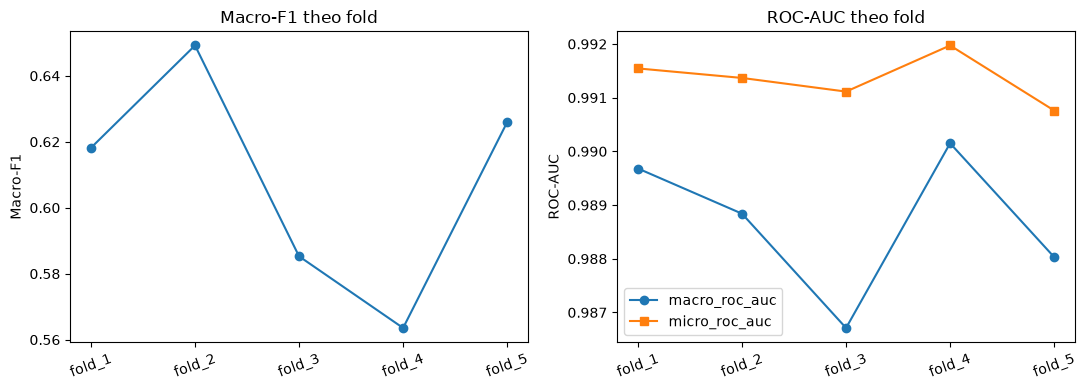

In [11]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(fold_metrics["fold"], fold_metrics["macro_f1"], marker="o")
axes[0].set_title("Macro-F1 theo fold")
axes[0].set_ylabel("Macro-F1")
axes[0].tick_params(axis="x", rotation=20)

axes[1].plot(fold_metrics["fold"], fold_metrics["macro_roc_auc"], marker="o", label="macro_roc_auc")
axes[1].plot(fold_metrics["fold"], fold_metrics["micro_roc_auc"], marker="s", label="micro_roc_auc")
axes[1].set_title("ROC-AUC theo fold")
axes[1].set_ylabel("ROC-AUC")
axes[1].tick_params(axis="x", rotation=20)
axes[1].legend()

fig.tight_layout()
fig.savefig(RESULTS_DIR / f"{MODEL_NAME}_folds.png", dpi=150, bbox_inches="tight")
plt.show()

## 8. Kết quả từng nhãn

In [12]:
per_label = pd.read_csv(RESULTS_DIR / f"{MODEL_NAME}_fold_per_label.csv")

per_label_summary = (
    per_label.groupby("label")[["precision", "recall", "f1", "roc_auc", "support"]]
    .agg(["mean", "std"])
    .reindex(LABEL_COLUMNS)
    .round(4)
)
per_label_summary.to_csv(RESULTS_DIR / f"{MODEL_NAME}_fold_per_label_summary.csv")
per_label_summary

precision          recall              f1         roc_auc  \
                   mean     std    mean     std    mean     std    mean   
label                                                                     
toxic            0.8532  0.0559  0.7840  0.0608  0.8139  0.0090  0.9839   
severe_toxic     0.5362  0.0726  0.3594  0.1681  0.4020  0.0963  0.9905   
obscene          0.8246  0.0439  0.8571  0.0403  0.8389  0.0096  0.9940   
threat           0.5871  0.2494  0.3320  0.2617  0.3268  0.1786  0.9873   
insult           0.7371  0.0544  0.7740  0.0702  0.7511  0.0102  0.9878   
identity_hate    0.6328  0.0493  0.4464  0.0787  0.5179  0.0366  0.9885   

                      support          
                  std    mean     std  
label                                  
toxic          0.0013  3058.0  1.4142  
severe_toxic   0.0011   318.8  1.4832  
obscene        0.0005  1689.2  1.6432  
threat         0.0041    95.6  1.1402  
insult         0.0009  1574.8  1.4832  
identity_hate  0.0045   281.0  1.4142

## 9. So sánh với RoBERTa label dependency (RQ3)

Hai model dùng cùng 5 fold nên so sánh **theo cặp trên từng fold**: Δ = LD − standard.
Paired t-test là kết quả chính; Wilcoxon với n = 5 không bao giờ cho p < 0.05 (p nhỏ nhất 0.0625), chỉ để tham khảo.

In [14]:
from scipy import stats

# Kết quả RoBERTa LD từng fold (lấy từ output notebook train_roberta_label_dependency_folds)
ld = pd.DataFrame({
    "fold":          ["fold_1", "fold_2", "fold_3", "fold_4", "fold_5"],
    "rows":          [31896, 31895, 31895, 31895, 31895],
    "micro_f1":      [0.776976, 0.779493, 0.776811, 0.775399, 0.763631],
    "macro_f1":      [0.639883, 0.638159, 0.597861, 0.620637, 0.597890],
    "micro_roc_auc": [0.991930, 0.991258, 0.991395, 0.991367, 0.989795],
    "macro_roc_auc": [0.988605, 0.987688, 0.989140, 0.988754, 0.986433],
}).set_index("fold")

std = fold_metrics.query("split == 'test'").set_index("fold")
assert (std["rows"] == ld["rows"]).all(), "Số dòng các fold khác LD → hai model không dùng cùng fold!"

rows = []
for metric in key_metrics:
    delta = ld[metric] - std[metric]
    rows.append({
        "metric": metric,
        "standard": f"{std[metric].mean():.4f} ± {std[metric].std():.4f}",
        "LD": f"{ld[metric].mean():.4f} ± {ld[metric].std():.4f}",
        "delta (LD - std)": f"{delta.mean():+.4f} ± {delta.std():.4f}",
        "LD wins": f"{int((delta > 0).sum())}/5",
        "paired_t_p": round(stats.ttest_rel(ld[metric], std[metric]).pvalue, 4),
    })
paired = pd.DataFrame(rows).set_index("metric")
paired.to_csv(RESULTS_DIR / f"{REFERENCE}_vs_{MODEL_NAME}_paired.csv")
paired

,standard,LD,delta (LD - std),LD wins,paired_t_p
metric,,,,,
micro_f1,0.7742 ± 0.0038,0.7745 ± 0.0062,+0.0003 ± 0.0074,3/5,0.9325
macro_f1,0.6084 ± 0.0340,0.6189 ± 0.0206,+0.0105 ± 0.0326,3/5,0.5127
micro_roc_auc,0.9914 ± 0.0005,0.9911 ± 0.0008,-0.0002 ± 0.0006,2/5,0.4764
macro_roc_auc,0.9887 ± 0.0014,0.9881 ± 0.0011,-0.0006 ± 0.0017,1/5,0.4990


## 10. Dự đoán thử comment mới (model fold_1)

In [17]:
import joblib

from toxic_comments.cleaning import clean_light, clean_heavy

model_path = MODELS_DIR / "fold_1" / f"{MODEL_NAME}.joblib"
loaded_model = joblib.load(model_path)
print("Đã load:", model_path)

Loading weights: 100%|██████████| 197/197 [00:00<00:00, 9378.44it/s]
[transformers] RobertaModel LOAD REPORT from: roberta-base
Key                       | Status     | 
--------------------------+------------+-
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
pooler.dense.weight       | MISSING    | 
pooler.dense.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Đã load: /root/AI4SE_toxic_comments/models/fold_1/roberta_standard.joblib


In [18]:
new_comments = [
    "You are such an idiot, I hope something bad happens to you.",
    "Thanks so much for fixing this, really appreciate it!",
]

cleaned = pd.Series(new_comments).apply(clean_light).apply(clean_heavy)
scores = loaded_model.predict_proba(cleaned)
preds = (scores >= 0.5).astype(int)

result = pd.DataFrame({"comment_text": new_comments})
for i, label in enumerate(LABEL_COLUMNS):
    result[f"{label}_prob"] = scores[:, i].round(4)
    result[f"{label}_pred"] = preds[:, i]

pd.set_option("display.max_colwidth", 40)
result

,comment_text,toxic_prob,toxic_pred,severe_toxic_prob,severe_toxic_pred,obscene_prob,obscene_pred,threat_prob,threat_pred,insult_prob,insult_pred,identity_hate_prob,identity_hate_pred
0,"You are such an idiot, I hope someth...",0.9856,1,0.0398,0,0.5737,1,0.0054,0,0.9422,1,0.0057,0
1,"Thanks so much for fixing this, real...",0.0002,0,0.0001,0,0.0001,0,0.0001,0,0.0003,0,0.0006,0
